# CLIWOC: first look at the data

Climatological Database for the World's Oceans: weather observations from ship logbooks (Dutch, British, Spanish and French ships, mostly 1750–1850).

- Source page: https://historicalclimatology.com/cliwoc
- Field definitions: https://stvno.github.io/page/cliwoc/

The aim of this notebook is to understand what is in the data (coverage, quality, biases) before choosing the 2 visualisations.

**Get the data** (run once from the repo root):
```bash
mkdir -p data && curl -L -o data/CLIWOC21.tsv "https://media.githubusercontent.com/media/stvno/stvno.github.io/master/page/cliwoc/CLIWOC21.tsv"
```

In [1]:
from pathlib import Path
import calendar

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, LogNorm

# Works whether the notebook is started from the repo root or from notebooks/
ROOT = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
DATA = ROOT / "data" / "CLIWOC21.tsv"
assert DATA.exists(), f"Download the data first, expected it at {DATA}"

pd.set_option("display.max_columns", 60)
pd.set_option("display.max_rows", 200)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 60)

plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": "#e4e3df",
    "grid.linewidth": 0.6,
    "axes.edgecolor": "#8a8984",
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
})

# One fixed colour per nationality, used in every chart
NAT_ORDER = ["DUTCH", "BRITISH", "SPANISH", "FRENCH", "OTHER"]
NAT_COLORS = {"DUTCH": "#2a78d6", "BRITISH": "#eb6834", "SPANISH": "#1baf7a",
              "FRENCH": "#eda100", "OTHER": "#9a9893"}
# Sequential (single hue) colormap for counts; starts above white so small counts stay visible
SEQ = ListedColormap(plt.cm.Blues(np.linspace(0.25, 1, 256)))

## 1. Raw file: columns and fill rate

The file mixes two kinds of columns:
- **IMMA columns** (`YR, MO, DY, LAT, LON, D, W, SLP, AT, …`) are standardised, numeric, already converted to modern units.
- **CLIWOC logbook columns** (`ShipName, VoyageFrom, AllWindForces, Weather, …`) are the transcription of the original logbook, often as free text in the original language.

In [2]:
all_cols = pd.read_csv(DATA, sep="\t", nrows=0).columns
print(len(all_cols), "columns")
print(list(all_cols))

180 columns
['YR', 'MO', 'DY', 'HR', 'LAT', 'LON', 'latitude', 'longitude', 'IM', 'ATTC', 'TI', 'LI', 'DS', 'VS', 'NID', 'II', 'ID', 'C1', 'DI', 'D', 'WI', 'W', 'VI', 'VV', 'WW', 'W1', 'SLP', 'A', 'PPP', 'IT', 'AT', 'WBTI', 'WBT', 'DPTI', 'DPT', 'SI', 'SST', 'N', 'NH', 'CL', 'HI', 'H', 'CM', 'CH', 'WD', 'WP', 'WH', 'SD', 'SP', 'SH', 'ATTI', 'ATTL', 'ATTE', 'InstAbbr', 'InstName', 'InstPlace', 'InstLand', 'NumberEntry', 'NameArchiveSet', 'ArchivePart', 'Specification', 'LogbookIdent', 'LogbookLanguage', 'ImageNumber', 'Illustr', 'drLatDeg', 'drLatMin', 'drLatSec', 'drLatHem', 'drLongDeg', 'drLongMin', 'drLongSec', 'drLongHem', 'LatDeg', 'LatMin', 'LatSec', 'LatHem', 'LongDeg', 'LongMin', 'LongSec', 'LongHem', 'LatInd', 'LonInd', 'ZeroMeridian', 'LMname1', 'LMdirection1', 'LMdistance1', 'LMname2', 'LMdirection2', 'LMdistance2', 'LMname3', 'LMdirection3', 'LMdistance3', 'PosCoastal', 'Calendar', 'Year', 'Month', 'Day', 'TimeOB', 'DayOfTheWeek', 'PartDay', 'Watch', 'Glasses', 'StartDay', '

In [3]:
%%time
# Takes ~30-60 s (160 MB)
raw = pd.read_csv(DATA, sep="\t", low_memory=False)
print(raw.shape)

(287116, 180)
CPU times: user 3.6 s, sys: 480 ms, total: 4.08 s
Wall time: 4.21 s


In [4]:
raw.head(3).T

,0,1,2
YR,1827,1827,1827
MO,8,8,8
DY,16,17,18
HR,500,500,500
LAT,-692,-827,-943
LON,10310,10047,9772
latitude,-6.92,-8.27,-9.43
longitude,103.1,100.47,97.72
IM,0,0,0
ATTC,1,1,1


In [5]:
profile = pd.DataFrame({
    "filled_pct": (raw.notna().mean() * 100).round(1),
    "n_unique": raw.nunique(),
    "example": [raw[c].dropna().iloc[0] if raw[c].notna().any() else None for c in raw.columns],
})
print(f"{(profile['filled_pct'] == 0).sum()} of {len(profile)} columns are completely empty")
profile.query("filled_pct > 0").sort_values("filled_pct", ascending=False)

41 of 180 columns are completely empty


,filled_pct,n_unique,example
YR,100.0,120,1827
LogbookIdent,100.0,1758,MAR_D23905_1164
Illustr,100.0,3,0
LatInd,100.0,7,1.0
LonInd,100.0,7,2
ZeroMeridian,100.0,720,GREENWICH
PosCoastal,100.0,2,0.0
Calendar,100.0,2,2.0
Year,100.0,118,1827.0
Month,100.0,12,8.0


### Columns that matter most

| Column | Meaning |
|---|---|
| `Year`, `Month`, `Day` | date of the logbook entry (usually one entry per day, at noon) |
| `latitude`, `longitude` | position in decimal degrees (N and E positive), mostly from dead reckoning |
| `D` | wind direction in degrees, the direction the wind blows **from**; `361` = calm, `362` = variable |
| `W` | wind speed in **0.1 m/s**, converted from the verbal force terms (Beaufort equivalents) |
| `AllWindDirections`, `AllWindForces` | the original wind wording from the logbook |
| `SLP` / `AT` | sea level pressure in 0.1 hPa / air temperature in 0.1 °C (only a minority of records) |
| `Nationality`, `ShipName`, `ShipType`, `Company` | who made the observation |
| `LogbookIdent`, `VoyageIni` | logbook ID and voyage start date (`YYYYMMDD`); together they identify a voyage |
| `VoyageFrom`, `VoyageTo` | port of departure and destination, as written in the logbook |
| `Distance` + `DistTravelledUnits` | distance sailed, in the **original units** (Dutch miles, leagues, nm…), so not directly comparable |
| `Gusts`, `Rain`, `Fog`, `Snow`, `Thunder`, `Hail`, `SeaIce` | 0/1 weather flags |

## 2. Clean working subset

Keep the useful columns, convert to numbers, drop broken rows and add derived wind features.

In [6]:
KEEP = [
    # when / where (standardised)
    "Year", "Month", "Day", "latitude", "longitude",
    # wind (standardised) + original wording
    "D", "W", "AllWindDirections", "AllWindForces",
    # other instruments / weather
    "SLP", "AT", "Weather", "Gusts", "Rain", "Fog", "Snow", "Thunder", "Hail", "SeaIce",
    # ship and voyage
    "Nationality", "LogbookLanguage", "ShipName", "ShipType", "Company", "LogbookIdent",
    "VoyageIni", "VoyageFrom", "VoyageTo", "Anchored", "Distance", "DistTravelledUnits", "Release",
]
df = raw[KEEP].copy()

for c in ["Year", "Month", "Day", "latitude", "longitude", "D", "W", "SLP", "AT", "Distance"]:
    df[c] = pd.to_numeric(df[c], errors="coerce")

n_before = len(df)
df = df[df["Year"].notna() & df["Month"].between(1, 12) & df["Day"].between(1, 31)]
df = df.astype({"Year": int, "Month": int, "Day": int})
print(f"dropped {n_before - len(df)} rows with a broken date")

# Impossible coordinates -> NaN (keep the row, it may still have wind info)
bad_pos = ~df["latitude"].between(-90, 90) | ~df["longitude"].between(-180, 180)
df.loc[bad_pos, ["latitude", "longitude"]] = np.nan
print(f"{df['latitude'].isna().mean():.1%} of rows have no position")

# pandas timestamps start in 1677, so 17th-century records (and impossible dates like 30 Feb) get NaT
df["date"] = pd.to_datetime(df[["Year", "Month", "Day"]].rename(columns=str.lower), errors="coerce")
print(f"{df['date'].isna().sum()} rows without a valid date")

dropped 3 rows with a broken date
9.2% of rows have no position
375 rows without a valid date


In [7]:
# Wind features
df["calm"] = df["D"].eq(361)
df["variable_wind"] = df["D"].eq(362)
df["wind_dir"] = df["D"].where(df["D"].between(1, 360))   # degrees the wind blows FROM, 360 = N
df["wind_ms"] = df["W"] / 10                               # W is stored in 0.1 m/s

BF_EDGES = [0, 0.3, 1.6, 3.4, 5.5, 8.0, 10.8, 13.9, 17.2, 20.8, 24.5, 28.5, 32.7, np.inf]
df["beaufort"] = pd.cut(df["wind_ms"], BF_EDGES, right=False, labels=range(13)).astype(float)

# Vector components (where the air flows TO). Average these, never the angles:
# the mean of 350° and 10° must be 0°, not 180°.
rad = np.deg2rad(df["wind_dir"])
df["u"] = -df["wind_ms"] * np.sin(rad)   # eastward
df["v"] = -df["wind_ms"] * np.cos(rad)   # northward
df.loc[df["calm"], ["u", "v"]] = 0.0

# Grouping helpers
df["nat"] = df["Nationality"].where(df["Nationality"].isin(NAT_ORDER[:-1]), "OTHER")
df["voyage_id"] = df["LogbookIdent"].astype(str) + " | " + df["VoyageIni"].astype(str)

df.head()

,Year,Month,Day,latitude,longitude,D,W,AllWindDirections,AllWindForces,SLP,AT,Weather,Gusts,Rain,Fog,Snow,Thunder,Hail,SeaIce,Nationality,LogbookLanguage,ShipName,ShipType,Company,LogbookIdent,VoyageIni,VoyageFrom,VoyageTo,Anchored,Distance,DistTravelledUnits,Release,date,calm,variable_wind,wind_dir,wind_ms,beaufort,u,v,nat,voyage_id
0,1827,8,16,-6.92,103.10,136.0,NaN,ZO,NaN,NaN,NaN,GOED WEER,0.0,0.0,0.0,0.0,0.0,0.0,0.0,DUTCH,DUTCH,ABEL TASMAN,NaN,MAR,MAR_D23905_1164,18270816,BATAVIA,NEDERLAND,0,30.75,ENGELSE,CLIWOC VERSION 1.0,1827-08-16,False,False,136.0,NaN,NaN,NaN,NaN,DUTCH,MAR_D23905_1164 | 18270816
1,1827,8,17,-8.27,100.47,135.0,46.0,ZO,BRAMZEILSKOELTE EN MINDERE KOELTE,NaN,NaN,GOED WEER,0.0,0.0,0.0,0.0,0.0,0.0,0.0,DUTCH,DUTCH,ABEL TASMAN,NaN,MAR,MAR_D23905_1164,18270816,BATAVIA,NEDERLAND,0,41.75,ENGELSE,CLIWOC VERSION 1.0,1827-08-17,False,False,135.0,4.6,3.0,-3.252691,3.252691,DUTCH,MAR_D23905_1164 | 18270816
2,1827,8,18,-9.43,97.72,135.0,46.0,ZO,BRAMZEILSKOELTE EN MINDERE KOELTE,NaN,NaN,GOED WEER,0.0,0.0,0.0,0.0,0.0,0.0,0.0,DUTCH,DUTCH,ABEL TASMAN,NaN,MAR,MAR_D23905_1164,18270816,BATAVIA,NEDERLAND,0,42.00,ENGELSE,CLIWOC VERSION 1.0,1827-08-18,False,False,135.0,4.6,3.0,-3.252691,3.252691,DUTCH,MAR_D23905_1164 | 18270816
3,1827,8,19,-10.77,95.02,135.0,46.0,ZO,BRAMZEILSKOELTE EN MINDERE KOELTE,NaN,NaN,GOED WEER,0.0,0.0,0.0,0.0,0.0,0.0,0.0,DUTCH,DUTCH,ABEL TASMAN,NaN,MAR,MAR_D23905_1164,18270816,BATAVIA,NEDERLAND,0,41.75,ENGELSE,CLIWOC VERSION 1.0,1827-08-19,False,False,135.0,4.6,3.0,-3.252691,3.252691,DUTCH,MAR_D23905_1164 | 18270816
4,1827,8,20,-12.07,92.83,113.0,26.0,OZO,FLAUWE BRAMZEILSKOELTE,NaN,NaN,GOED WEER,0.0,0.0,0.0,0.0,0.0,0.0,0.0,DUTCH,DUTCH,ABEL TASMAN,NaN,MAR,MAR_D23905_1164,18270816,BATAVIA,NEDERLAND,0,37.50,ENGELSE,CLIWOC VERSION 1.0,1827-08-20,False,False,113.0,2.6,2.0,-2.393313,1.015901,DUTCH,MAR_D23905_1164 | 18270816


## 3. Who is in the data?

The data is a sample of the logbooks that **survived and were digitised**, not of all ships at sea. Every count below is shaped by that.

In [8]:
pd.Series({
    "records": f"{len(df):,}",
    "logbooks": df["LogbookIdent"].nunique(),
    "voyages (logbook + start date)": df["voyage_id"].nunique(),
    "ships": df["ShipName"].nunique(),
    "years": f"{df['Year'].min()}–{df['Year'].max()}",
    "share in 1750–1850": f"{df['Year'].between(1750, 1850).mean():.1%}",
    "with position": f"{df['latitude'].notna().mean():.1%}",
    "with wind direction (incl. calm/variable)": f"{df['D'].notna().mean():.1%}",
    "with wind speed": f"{df['wind_ms'].notna().mean():.1%}",
    "with pressure (SLP)": f"{df['SLP'].notna().mean():.1%}",
    "with air temperature (AT)": f"{df['AT'].notna().mean():.1%}",
}).to_frame("value")

,value
records,"287,113"
logbooks,1757
voyages (logbook + start date),5426
ships,974
years,1662–1855
share in 1750–1850,94.9%
with position,90.8%
with wind direction (incl. calm/variable),96.4%
with wind speed,85.2%
with pressure (SLP),18.1%


In [9]:
nat_tab = df.groupby("Nationality").agg(
    records=("Year", "size"),
    logbooks=("LogbookIdent", "nunique"),
    ships=("ShipName", "nunique"),
    first_year=("Year", "min"),
    last_year=("Year", "max"),
).sort_values("records", ascending=False)
nat_tab["share"] = (nat_tab["records"] / nat_tab["records"].sum()).map("{:.1%}".format)
nat_tab

,records,logbooks,ships,first_year,last_year,share
Nationality,,,,,,
DUTCH,126402,633,328,1662,1855,44.0%
BRITISH,94859,670,413,1750,1829,33.0%
SPANISH,54115,432,179,1675,1849,18.8%
FRENCH,10631,19,77,1746,1837,3.7%
SWEDISH,700,2,2,1748,1752,0.2%
AMERICAN,276,2,3,1807,1819,0.1%
HAMBURG,68,1,1,1797,1797,0.0%
DANISH,62,1,1,1798,1798,0.0%


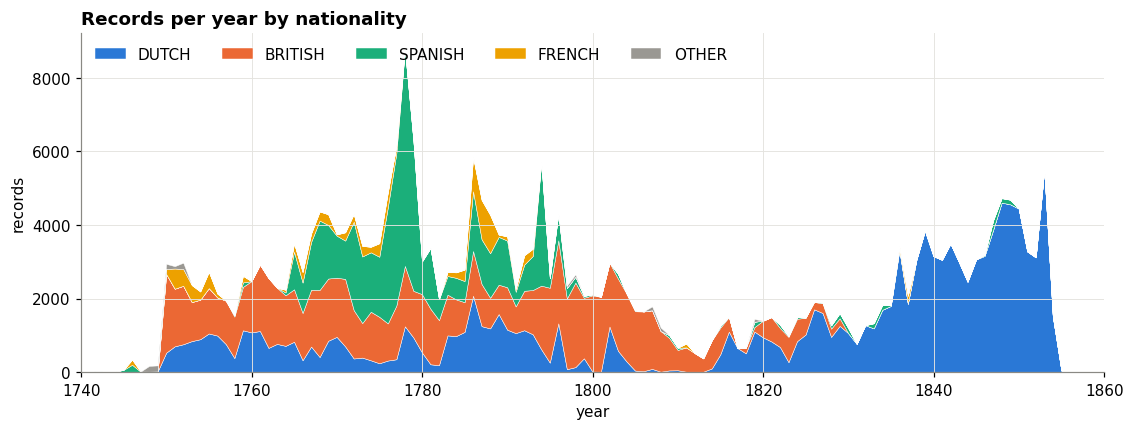

records before 1740: 411


In [10]:
years = range(df["Year"].min(), df["Year"].max() + 1)
per_year = (df.groupby(["Year", "nat"]).size().unstack(fill_value=0)
              .reindex(index=years, columns=NAT_ORDER, fill_value=0))

fig, ax = plt.subplots(figsize=(12, 4))
ax.stackplot(per_year.index, per_year.T.values, labels=NAT_ORDER,
             colors=[NAT_COLORS[n] for n in NAT_ORDER], edgecolor="white", linewidth=0.3)
ax.set(title="Records per year by nationality", xlabel="year", ylabel="records", xlim=(1740, 1860))
ax.legend(loc="upper left", frameon=False, ncol=5)
plt.show()

print("records before 1740:", (df["Year"] < 1740).sum())

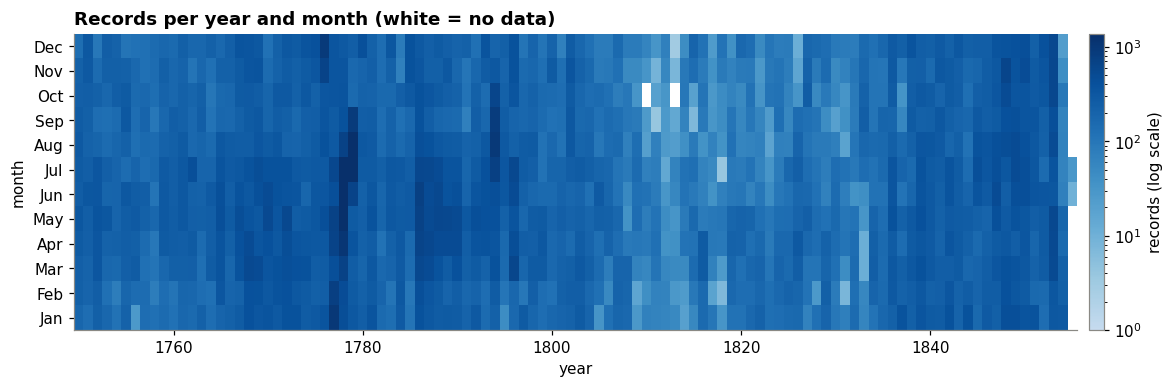

In [11]:
ym = (df[df["Year"].between(1750, 1855)].groupby(["Year", "Month"]).size().unstack(fill_value=0)
        .reindex(index=range(1750, 1856), columns=range(1, 13), fill_value=0))

fig, ax = plt.subplots(figsize=(14, 3.5))
im = ax.imshow(ym.T, aspect="auto", origin="lower", cmap=SEQ, norm=LogNorm(vmin=1),
               extent=[1749.5, 1855.5, 0.5, 12.5])
ax.set(title="Records per year and month (white = no data)", xlabel="year", ylabel="month",
       yticks=range(1, 13), yticklabels=calendar.month_abbr[1:])
ax.grid(False)
fig.colorbar(im, ax=ax, label="records (log scale)", pad=0.01)
plt.show()

## 4. Where are the observations?

No basemap needed: with ~270k positions the shipping lanes (and therefore the coastlines) draw themselves.

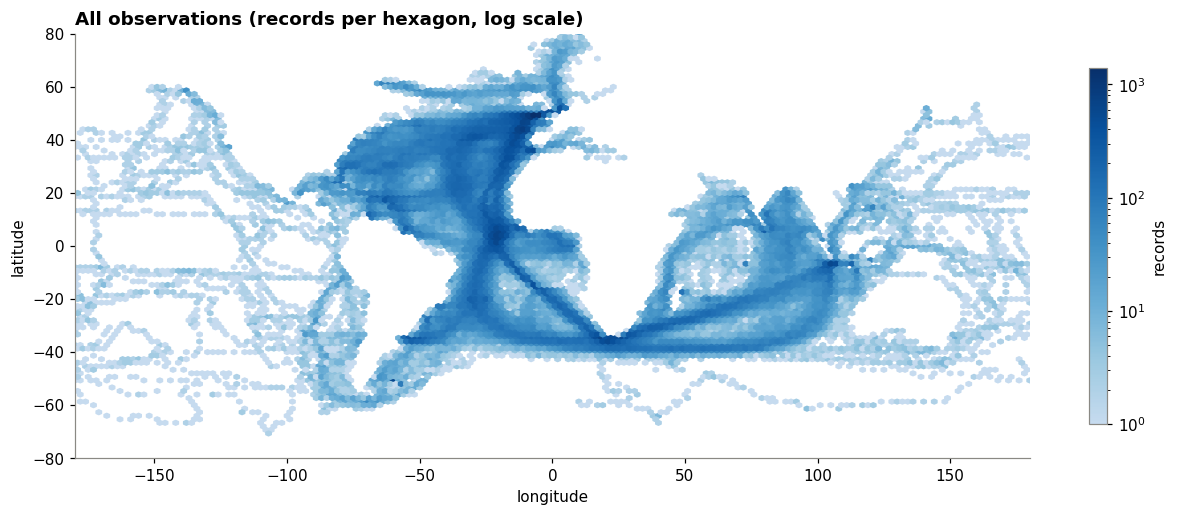

In [12]:
pos = df.dropna(subset=["latitude", "longitude"])

fig, ax = plt.subplots(figsize=(14, 7))
hb = ax.hexbin(pos["longitude"], pos["latitude"], gridsize=(180, 60), extent=(-180, 180, -80, 80),
               bins="log", mincnt=1, cmap=SEQ)
ax.set(title="All observations (records per hexagon, log scale)", xlabel="longitude", ylabel="latitude",
       xlim=(-180, 180), ylim=(-80, 80), aspect="equal")
ax.grid(False)
fig.colorbar(hb, ax=ax, shrink=0.6, label="records")
plt.show()

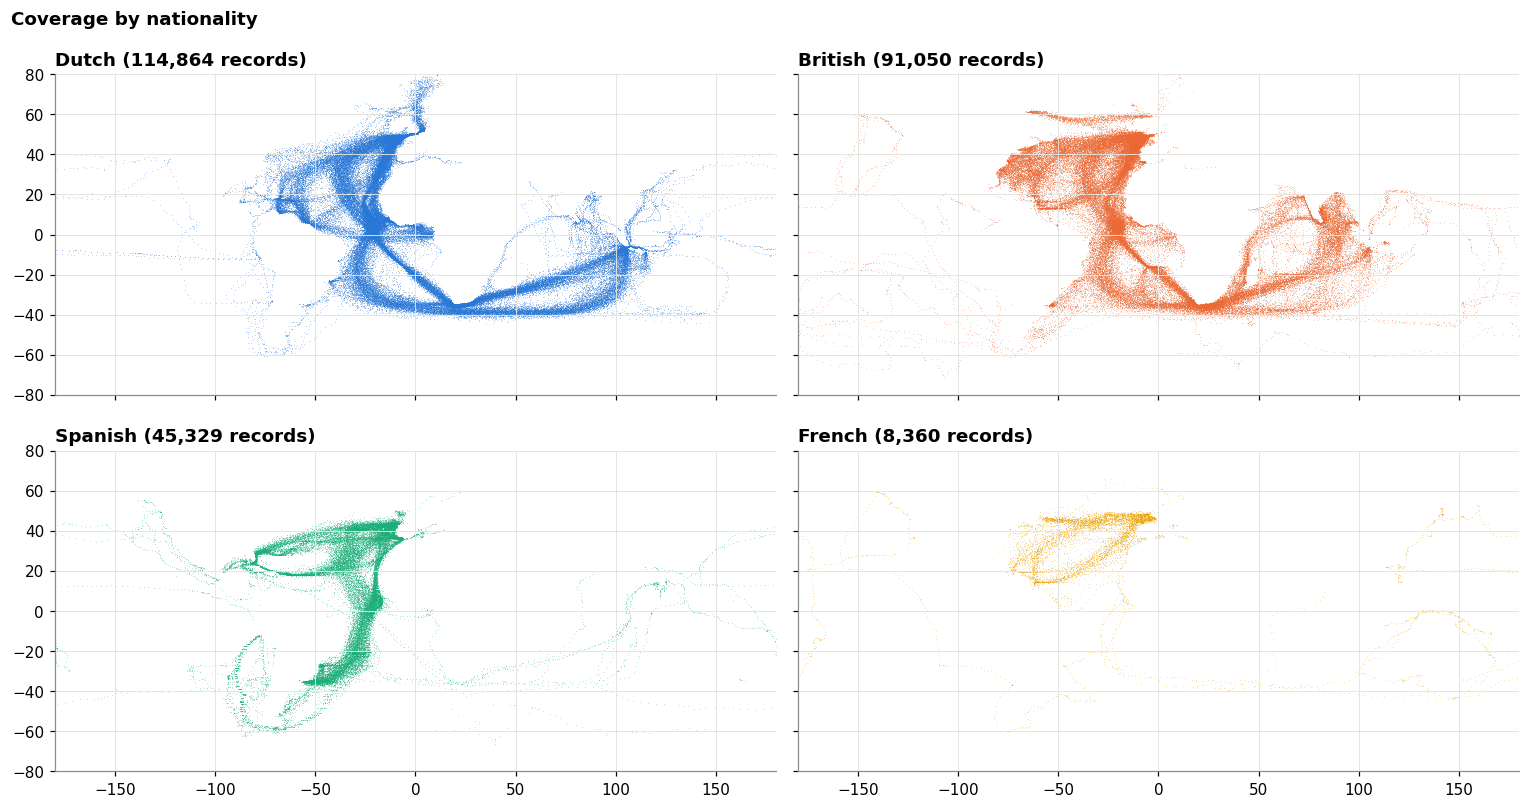

In [13]:
fig, axes = plt.subplots(2, 2, figsize=(14, 7.5), sharex=True, sharey=True)
for ax, nat in zip(axes.flat, NAT_ORDER[:4]):
    sub = pos[pos["nat"] == nat]
    ax.scatter(sub["longitude"], sub["latitude"], s=0.3, alpha=0.3, linewidths=0,
               color=NAT_COLORS[nat], rasterized=True)
    ax.set(title=f"{nat.title()} ({len(sub):,} records)", xlim=(-180, 180), ylim=(-80, 80), aspect="equal")
fig.suptitle("Coverage by nationality", fontweight="bold", x=0.01, ha="left")
plt.tight_layout()
plt.show()

## 5. Logbooks and voyages

Ideas like speed, routes and voyage duration need consecutive positions of the same voyage, so check how voyages are recorded.

In [14]:
voy = df.groupby("voyage_id").agg(
    nat=("nat", "first"),
    ship=("ShipName", "first"),
    origin=("VoyageFrom", "first"),
    dest=("VoyageTo", "first"),
    start=("date", "min"),
    end=("date", "max"),
    n=("Year", "size"),
    n_pos=("latitude", "count"),
)
voy["days"] = (voy["end"] - voy["start"]).dt.days
print(voy[["n", "n_pos", "days"]].describe().round(1))
voy.sort_values("n", ascending=False).head(10)

            n   n_pos     days
count  5426.0  5426.0   5423.0
mean     52.9    48.0     64.0
std      46.8    41.3    199.7
min       1.0     0.0      0.0
25%      17.0    15.0     17.0
50%      40.0    37.0     43.0
75%      76.0    72.0     83.0
max     775.0   371.0  11985.0


,nat,ship,origin,dest,start,end,n,n_pos,days
voyage_id,,,,,,,,,
NMM ADM/L/S594 | nan,BRITISH,SWIFT,None,None,1766-10-17,1769-09-30,775,38,1079.0
NMM ADM/L/F59 | nan,BRITISH,FAVORITE,None,None,1768-11-27,1770-09-11,499,371,653.0
"EXTRACT B, REIS 1B, P.10-19 | 18510512",DUTCH,MAGDALENA,BATAVIA,KAAP DE GOEDE HOOP,1851-05-12,1851-09-20,445,231,131.0
"EXTRACT B, REIS 1A, P.2-9 | 18530224",DUTCH,MAGDALENA,LONDEN,CALCUTTA,1853-02-24,1853-06-12,436,216,108.0
"EXTRACT B, REIS 1B, P.10-19 | 18500918",DUTCH,MAGDALENA,NIEUWEDIEP,CALCUTTA,1850-09-18,1851-02-04,412,136,139.0
1-274_S431(8) | nan,DUTCH,FRANKENDAAL,FISHING GROUNDS,None,1788-05-21,1792-07-17,389,1,1518.0
"EXTRACT D, REIS 1, P.1-43 | 18260105",DUTCH,ROTTERDAMS WELVAREN,ROTTERDAM,BATAVIA,1826-01-05,1826-05-03,356,116,118.0
"CORREOS, 192A R1 | 17671215",SPANISH,LA PRINCESA,LA CORUÑA,MONTEVIDEO,1767-12-15,1768-04-20,353,111,127.0
ADM_177_2421 | 17890414,DUTCH,THETIS,TEXEL,BATAVIA,1789-04-14,1789-12-20,345,328,250.0


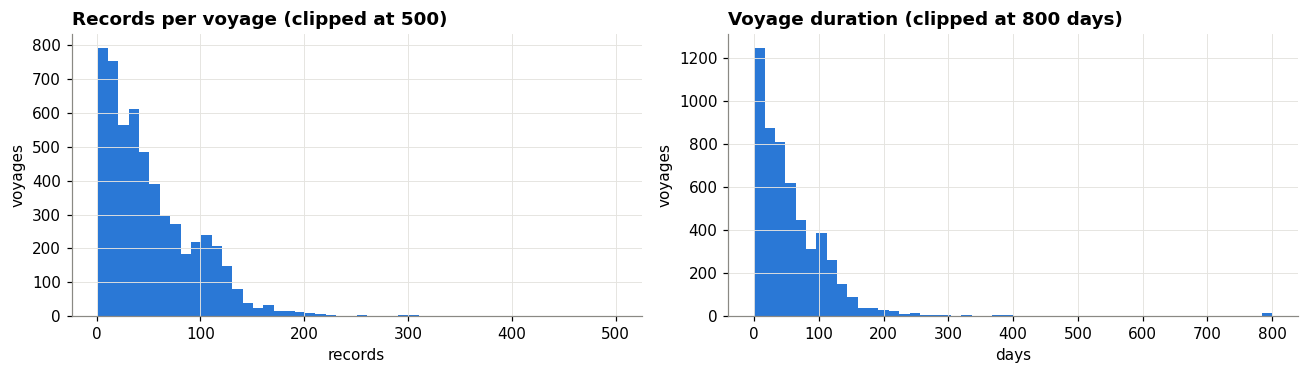

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
axes[0].hist(voy["n"].clip(upper=500), bins=50, color=NAT_COLORS["DUTCH"])
axes[0].set(title="Records per voyage (clipped at 500)", xlabel="records", ylabel="voyages")
axes[1].hist(voy["days"].dropna().clip(upper=800), bins=50, color=NAT_COLORS["DUTCH"])
axes[1].set(title="Voyage duration (clipped at 800 days)", xlabel="days", ylabel="voyages")
plt.tight_layout()
plt.show()

In [16]:
# Most common routes, as written in the logbooks (original spelling and language)
voy.groupby(["origin", "dest"]).size().sort_values(ascending=False).head(20).to_frame("voyages")

voyages
origin             dest                       
LA CORUÑA          LA HABANA               141
LA HABANA          LA CORUÑA               134
LA CORUÑA          MONTEVIDEO               97
MONTEVIDEO         LA CORUÑA                93
ROTTERDAM          BATAVIA                  68
NEDERLAND          BATAVIA                  57
NIEUWEDIEP         BATAVIA                  50
BATAVIA            ROTTERDAM                44
                   NIEUWEDIEP               43
                   NEDERLAND                32
CÁDIZ              CÁDIZ                    30
COASTAL EAST INDIA COASTAL EAST INDIA       30
COASTAL            CARIBEAN                 28
JAMAICA            SPITHEAD                 24
CURACAO            HELLEVOETSLUIS           21
PARAMARIBO         CURACAO                  20
BATAVIA            HELLEVOETSLUIS           20
                   TEXEL                    20
SPITHEAD           BARBADOS                 18
                   MADEIRA                  18

In [17]:
# Time between consecutive records of the same voyage
d = df.dropna(subset=["date"]).sort_values(["voyage_id", "date"])
gap_days = d.groupby("voyage_id")["date"].diff().dt.days

print(gap_days.value_counts().sort_index().head(10).to_string())
print(f"\nsame day: {(gap_days == 0).mean():.1%}   next day: {(gap_days == 1).mean():.1%}   "
      f"longer gap: {(gap_days > 1).mean():.1%}")

date
0.0      7044
1.0    270787
2.0      1075
3.0       379
4.0       271
5.0       200
6.0       159
7.0       148
8.0       120
9.0       117

same day: 2.5%   next day: 94.4%   longer gap: 1.2%


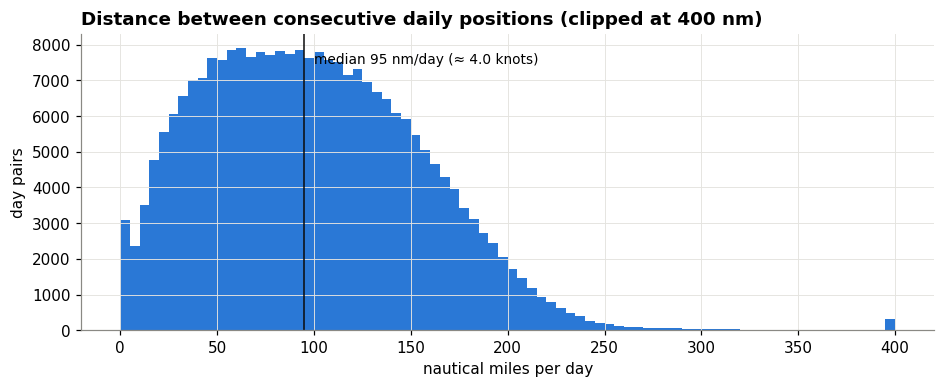

1.3% of day pairs moved < 5 nm (at anchor / in port?)
0.2% moved > 300 nm (probably position errors)


In [18]:
def haversine_nm(lat1, lon1, lat2, lon2):
    lat1, lon1, lat2, lon2 = map(np.deg2rad, (lat1, lon1, lat2, lon2))
    a = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
    return 2 * 3440.065 * np.arcsin(np.sqrt(a))   # Earth radius in nautical miles

g = d.groupby("voyage_id")
step_nm = haversine_nm(g["latitude"].shift(), g["longitude"].shift(), d["latitude"], d["longitude"])
daily_nm = step_nm[gap_days == 1].dropna()

fig, ax = plt.subplots(figsize=(10, 3.5))
ax.hist(daily_nm.clip(upper=400), bins=80, color=NAT_COLORS["DUTCH"])
ax.axvline(daily_nm.median(), color="#0b0b0b", linewidth=1)
ax.text(daily_nm.median() + 5, ax.get_ylim()[1] * 0.9, f"median {daily_nm.median():.0f} nm/day "
        f"(≈ {daily_nm.median() / 24:.1f} knots)", fontsize=9)
ax.set(title="Distance between consecutive daily positions (clipped at 400 nm)",
       xlabel="nautical miles per day", ylabel="day pairs")
plt.show()
print(f"{(daily_nm < 5).mean():.1%} of day pairs moved < 5 nm (at anchor / in port?)")
print(f"{(daily_nm > 300).mean():.1%} moved > 300 nm (probably position errors)")

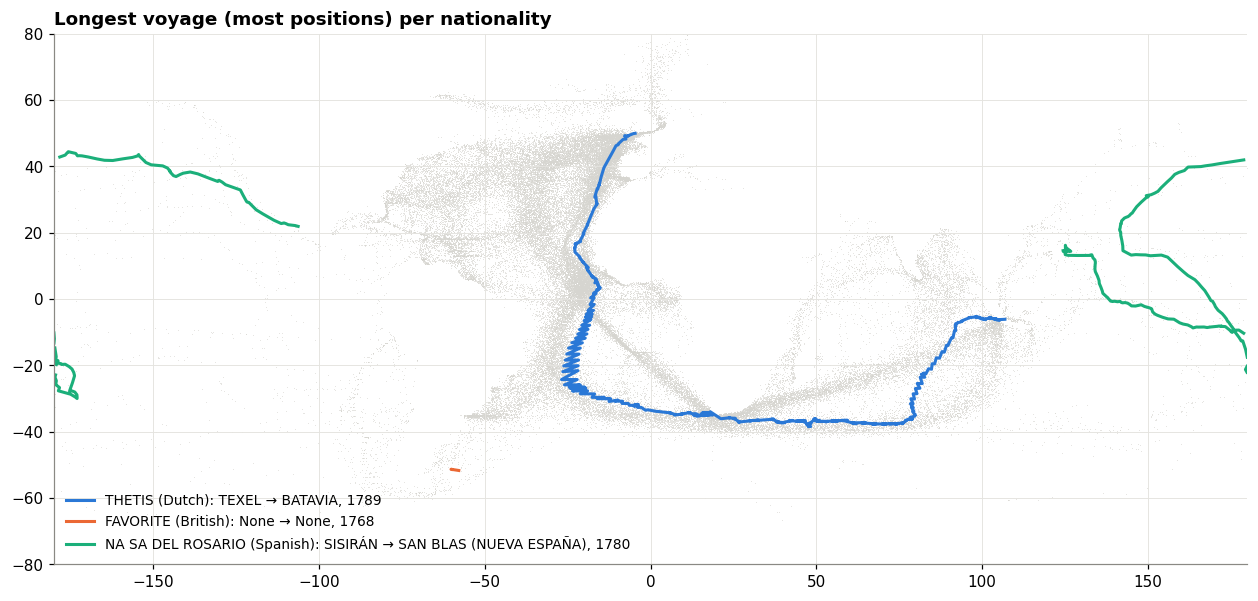

In [19]:
def plot_track(ax, lon, lat, **kw):
    # break the line where a voyage crosses the 180° meridian
    lon, lat = np.asarray(lon, float), np.asarray(lat, float)
    jump = np.where(np.abs(np.diff(lon)) > 180)[0] + 1
    ax.plot(np.insert(lon, jump, np.nan), np.insert(lat, jump, np.nan), **kw)

examples = {nat: voy.loc[voy["nat"] == nat, "n_pos"].idxmax() for nat in ["DUTCH", "BRITISH", "SPANISH"]}
bg = pos.sample(80_000, random_state=0)

fig, ax = plt.subplots(figsize=(14, 7))
ax.scatter(bg["longitude"], bg["latitude"], s=0.2, color="#d6d5d0", linewidths=0, rasterized=True)
for nat, vid in examples.items():
    t = d[d["voyage_id"] == vid].dropna(subset=["latitude", "longitude"])
    v = voy.loc[vid]
    plot_track(ax, t["longitude"], t["latitude"], color=NAT_COLORS[nat], linewidth=2,
               label=f"{v['ship']} ({nat.title()}): {v['origin']} → {v['dest']}, {v['start'].year}")
ax.set(title="Longest voyage (most positions) per nationality", xlim=(-180, 180), ylim=(-80, 80), aspect="equal")
ax.legend(loc="lower left", frameon=False, fontsize=9)
plt.show()

## 6. Wind

The core of the dataset. Directions come from a 32-point compass (steps of 11.25°), speeds from verbal force terms translated to Beaufort equivalents, so both are **discrete**.

In [20]:
print(pd.Series({
    "direction in degrees": df["wind_dir"].notna().mean(),
    "calm": df["calm"].mean(),
    "variable": df["variable_wind"].mean(),
    "no direction": df["D"].isna().mean(),
    "speed given": df["wind_ms"].notna().mean(),
}).map("{:.1%}".format).to_string())

print(f"\n{df['wind_dir'].nunique()} distinct directions, {df['wind_ms'].nunique()} distinct speeds")
df["wind_ms"].value_counts().sort_index().to_frame("records").T

direction in degrees    92.1%
calm                     0.8%
variable                 3.5%
no direction             3.6%
speed given             85.2%

360 distinct directions, 46 distinct speeds


wind_ms,0.0,0.1,0.6,1.0,1.2,1.5,2.0,2.3,2.6,2.9,4.0,4.4,4.6,4.9,5.4,6.1,6.7,7.3,8.0,8.7,9.3,10.0,11.6,12.3,12.6,13.1,13.8,13.9,14.7,15.4,16.3,17.1,17.2,18.1,19.0,19.8,21.7,22.6,23.5,25.5,26.8,27.4,29.5,30.9,31.6,35.0
records,8047,14,324,20143,329,26,1207,2,34321,1292,989,5,32114,3686,1,276,53761,908,1,158,40690,490,200,20508,47,291,2,1,57,6430,719,1,1,50,11392,74,21,4068,39,23,1437,125,1,229,20,32


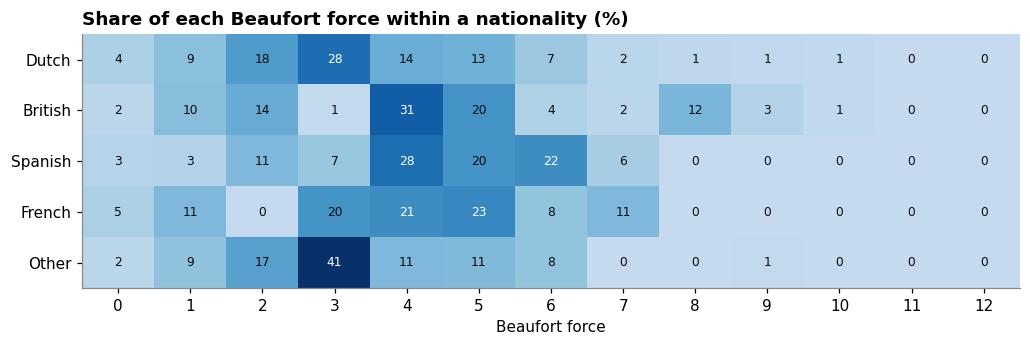

In [21]:
# Different languages describe wind force with different words.
# If the translation to Beaufort is consistent, nationalities sailing similar seas should look similar.
bf = pd.crosstab(df["nat"], df["beaufort"], normalize="index").reindex(NAT_ORDER) * 100

fig, ax = plt.subplots(figsize=(11, 3))
im = ax.imshow(bf.values, cmap=SEQ, aspect="auto")
ax.set(title="Share of each Beaufort force within a nationality (%)", xlabel="Beaufort force",
       xticks=range(bf.shape[1]), xticklabels=bf.columns.astype(int),
       yticks=range(len(bf)), yticklabels=bf.index.str.title())
ax.grid(False)
for i in range(bf.shape[0]):
    for j in range(bf.shape[1]):
        val = bf.values[i, j]
        ax.text(j, i, f"{val:.0f}", ha="center", va="center", fontsize=8,
                color="white" if val > np.nanmax(bf.values) / 2 else "#0b0b0b")
plt.show()

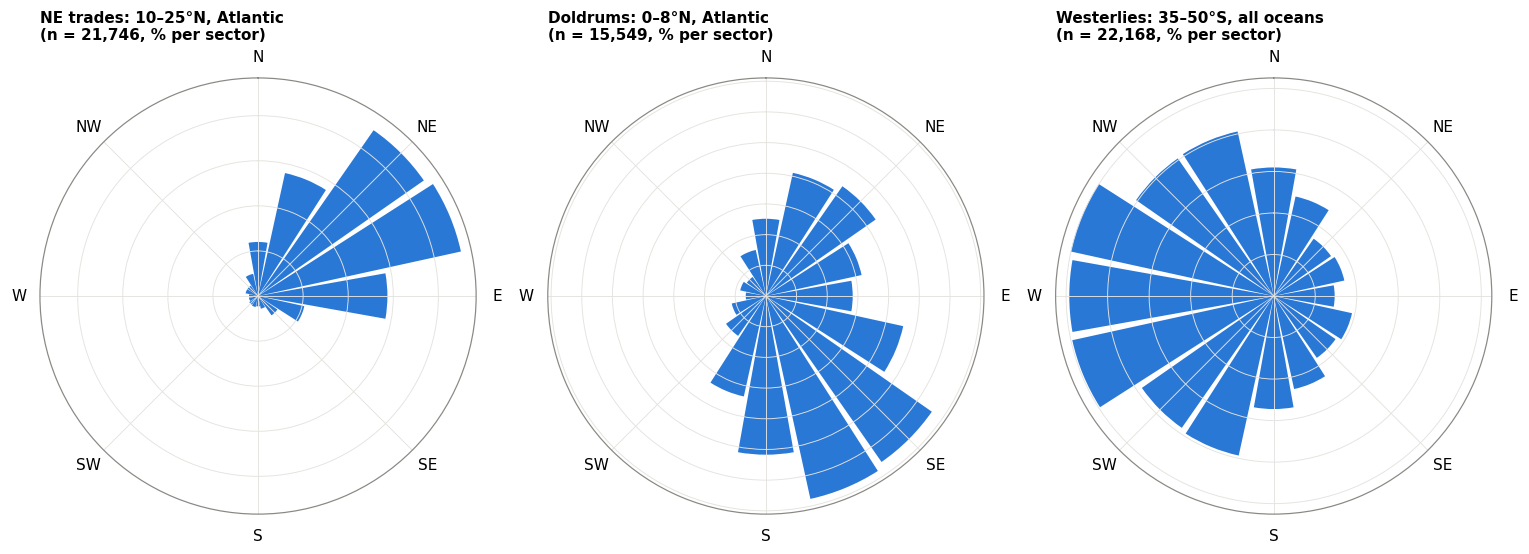

NE trades: 10–25°N, Atlantic: calm 0.5%, mean speed 6.9 m/s
Doldrums: 0–8°N, Atlantic: calm 1.5%, mean speed 4.6 m/s
Westerlies: 35–50°S, all oceans: calm 0.7%, mean speed 9.2 m/s


In [22]:
def wind_rose(ax, dirs, title):
    sector = ((dirs.dropna() + 11.25) // 22.5).astype(int) % 16       # 16 sectors, N centred on 0°
    share = np.bincount(sector, minlength=16) / len(sector) * 100
    theta = np.deg2rad(np.arange(16) * 22.5)
    ax.bar(theta, share, width=np.deg2rad(22.5) * 0.9, color=NAT_COLORS["DUTCH"])
    ax.set_theta_zero_location("N")
    ax.set_theta_direction(-1)
    ax.set_xticks(np.deg2rad(np.arange(0, 360, 45)), ["N", "NE", "E", "SE", "S", "SW", "W", "NW"])
    ax.set_yticklabels([])
    ax.set_title(f"{title}\n(n = {len(sector):,}, % per sector)", fontsize=10)

atlantic = df["longitude"].between(-60, 0)
regions = {
    "NE trades: 10–25°N, Atlantic": df[atlantic & df["latitude"].between(10, 25)],
    "Doldrums: 0–8°N, Atlantic": df[atlantic & df["latitude"].between(0, 8)],
    "Westerlies: 35–50°S, all oceans": df[df["latitude"].between(-50, -35)],
}
fig, axes = plt.subplots(1, 3, figsize=(14, 4.8), subplot_kw={"projection": "polar"})
for ax, (name, sub) in zip(axes, regions.items()):
    wind_rose(ax, sub["wind_dir"], name)
plt.tight_layout()
plt.show()

for name, sub in regions.items():
    print(f"{name}: calm {sub['calm'].mean():.1%}, mean speed {sub['wind_ms'].mean():.1f} m/s")

### Teaser: monsoon reversal in the northern Indian Ocean

Mean wind vector per calendar month in a box over the Arabian Sea and Bay of Bengal (0–20°N, 55–95°E). Arrows point where the air flows **to**.
*Steadiness* = length of the mean vector ÷ mean speed (1 = wind always from the same direction, 0 = directions cancel out).

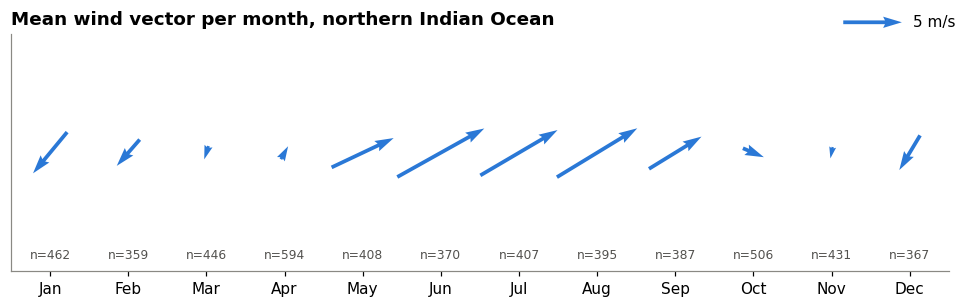

,u,v,mean_speed,n,vector_speed,from_deg,steadiness
Month,,,,,,,
1,-2.91,-3.52,5.78,462,4.56,39.61,0.79
2,-1.96,-2.24,4.92,359,2.98,41.11,0.61
3,-0.37,-1.13,4.06,446,1.19,17.89,0.29
4,0.61,1.10,4.20,594,1.26,209.11,0.30
5,5.29,2.50,7.58,408,5.86,244.70,0.77
6,7.42,4.14,9.88,370,8.50,240.84,0.86
7,6.59,3.87,8.68,407,7.64,239.59,0.88
8,6.85,4.17,9.20,395,8.02,238.68,0.87
9,4.48,2.75,7.17,387,5.26,238.46,0.73


In [23]:
box = df[df["latitude"].between(0, 20) & df["longitude"].between(55, 95) & df["u"].notna()]
mon = box.groupby("Month").agg(u=("u", "mean"), v=("v", "mean"), mean_speed=("wind_ms", "mean"), n=("u", "count"))
mon["vector_speed"] = np.hypot(mon["u"], mon["v"])
mon["from_deg"] = np.rad2deg(np.arctan2(-mon["u"], -mon["v"])) % 360
mon["steadiness"] = mon["vector_speed"] / mon["mean_speed"]

fig, ax = plt.subplots(figsize=(11, 2.8))
q = ax.quiver(mon.index, np.zeros(len(mon)), mon["u"], mon["v"], color=NAT_COLORS["DUTCH"],
              scale=80, scale_units="width", pivot="middle", width=0.004)
ax.quiverkey(q, 0.95, 1.05, 5, "5 m/s", labelpos="E")
for m, n in mon["n"].items():
    ax.text(m, -0.9, f"n={n}", ha="center", fontsize=8, color="#52514e")
ax.set(xlim=(0.5, 12.5), ylim=(-1, 1), xticks=range(1, 13), xticklabels=calendar.month_abbr[1:], yticks=[],
       title="Mean wind vector per month, northern Indian Ocean")
ax.grid(False)
plt.show()
mon.round(2)

## 7. Instruments and free text

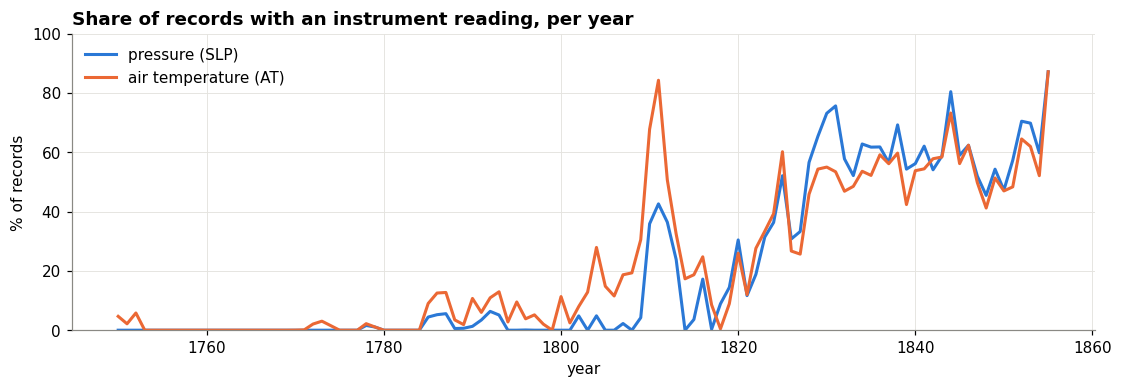

In [24]:
cov = (df[df["Year"].between(1750, 1855)]
       .assign(pressure=df["SLP"].notna(), air_temperature=df["AT"].notna())
       .groupby("Year")[["pressure", "air_temperature"]].mean() * 100)

fig, ax = plt.subplots(figsize=(12, 3.5))
ax.plot(cov.index, cov["pressure"], color=NAT_COLORS["DUTCH"], linewidth=2, label="pressure (SLP)")
ax.plot(cov.index, cov["air_temperature"], color=NAT_COLORS["BRITISH"], linewidth=2, label="air temperature (AT)")
ax.set(title="Share of records with an instrument reading, per year", xlabel="year", ylabel="% of records", ylim=(0, 100))
ax.legend(frameon=False)
plt.show()

In [25]:
# Most common original wind-force wording per logbook language
for language, s in df["AllWindForces"].dropna().groupby(df["LogbookLanguage"]):
    print(f"\n=== {language} ({len(s):,} records, {s.nunique():,} distinct phrases)")
    print(s.str.strip().str.upper().value_counts().head(8).to_string())


=== DUTCH (115,378 records, 10,843 distinct phrases)
AllWindForces
5                  10323
BRAMZEILSKOELTE     9769
4                   8167
3                   6872
2                   5571
6                   4812
FLAUWE KOELTE       3236
1                   2869

=== ENGLISH (92,158 records, 21,632 distinct phrases)
AllWindForces
MODERATE                   10395
FRESH BREEZES               7273
MODERATE BREEZES            4378
FRESH GALES                 4311
LIGHT BREEZES               4276
LIGHT AIRS                  3291
FRESH GALES AND SQUALLY     1378
LIGHT WINDS                 1056

=== FRENCH (9,348 records, 749 distinct phrases)
AllWindForces
BON FRAIS       1655
PETITE FRAIS    1144
JOLIE FRAIS      490
PETIT FRAIS      394
VARIABLE         375
FRAIS            373
PETITE VENT      286
GRAND FRAIS      283

=== SPANISH (42,102 records, 1,855 distinct phrases)
AllWindForces
BONANCIBLE    8933
FRESQUITO     7599
FRESCO        7312
FLOJO         2456
CALMOSO       2438
CALM

## 8. Save the clean subset

Later notebooks can load this instead of the 160 MB TSV.

In [26]:
OUT = ROOT / "data" / "cliwoc_clean.pkl"
df.to_pickle(OUT)
print(f"saved {len(df):,} rows × {df.shape[1]} columns to {OUT}")

saved 287,113 rows × 42 columns to /Users/nebodigatreba7/Documents/Personal/Magisterij/intelligence-methods-project-ship-visualisation/data/cliwoc_clean.pkl


## What we learned

- **Who:** Dutch 44%, British 33%, Spanish 19%, French 4% of the records. Coverage shifts a lot over time: British logs only 1750–1829, a Spanish peak around 1777–78, few Dutch logs 1795–1814, almost only Dutch after 1830. So any trend over time is also a change in *who* is in the data.
- **Where:** Atlantic and Indian Ocean well covered, Pacific sparse.
- **Wind:** a direction in 96% of the records (incl. calm/variable), a speed in 85%. Directions behave as expected physically: NE trades, westerlies, and the monsoon reversal (wind from ~40° in January, from ~240° in June–August).
- **Wind force caveat:** each language's wind words were translated to Beaufort differently (British logs: 1% at force 3 but 12% at force 8; Dutch logs peak at force 3). Don't compare wind force between nationalities without checking.
- **Daily positions:** 94% of consecutive records of a voyage are exactly 1 day apart, median 95 nm/day ≈ 4 knots, so ship speed can be computed.
- **Instruments:** pressure and air temperature only in ~19% of the records, mostly after 1810.

**Which ideas are feasible** (counted in a quick side check, not in this notebook):
- strong: monthly wind atlas (146 cells of 5° with ≥ 20 observations in all 12 months), sailing performance (~205k day pairs with wind), voyage duration (La Coruña → Havana 141 voyages, Netherlands → Batavia 225);
- too thin: Australia (1,060 records nearby), 1816 in the English Channel (23 records), storm case studies (16 cases of ≥ 3 ships in a gale nearby).

**Chosen:** idea B, sailing performance, first (`02_sailing_performance.ipynb`); idea A, monthly wind atlas + PCA/SVD, next.